In [1]:
import pandas as pd
import numpy as np
import math

In [2]:
df = pd.read_csv("SZ_area_POI.csv",header=0,index_col=0)
data_np = np.array(df)
data_np_new = np.delete(data_np,0,1)

In [3]:
print(data_np_new.shape)
len = data_np_new.shape[0]

(247, 14)


In [4]:
TF = np.zeros_like(data_np_new)
for i in range(len):
    count = np.sum(data_np_new[i])
    for j in range (data_np_new.shape[1]):
        TF[i,j] = data_np_new[i,j]/count


In [5]:
IDF = np.zeros_like(data_np_new)
nozerocount = np.count_nonzero(data_np_new,axis=1)
for i in range(data_np_new.shape[1]):
    for j in range(len):
        IDF[j,i] = math.log(len/nozerocount[i])
TF_IDF = TF*IDF    

In [6]:
sim_corr = np.zeros((len,len))
for i in range(len):
    for j in range(len):
        vec1 = TF_IDF[i]
        vec2 = TF_IDF[j]
        sim_corr[i,j] = vec1.dot(vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

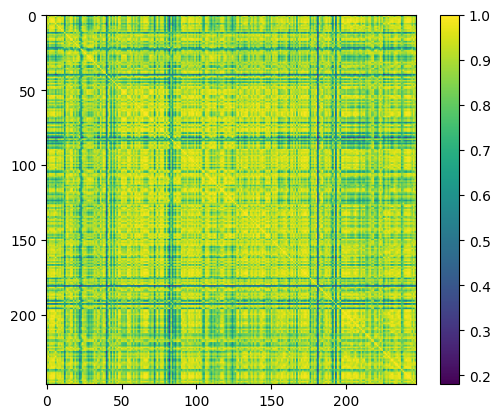

In [7]:
import matplotlib.pyplot as plt
plt.imshow(sim_corr)
plt.colorbar()

In [8]:
pd.DataFrame(data=sim_corr).to_csv("cos_sim.csv")

In [12]:
sim_mask = np.zeros((len,len))
for i in range(len):
    for j in range(len):
        if sim_corr[i,j]>=0.9:
            sim_mask[i,j] = sim_corr[i,j]

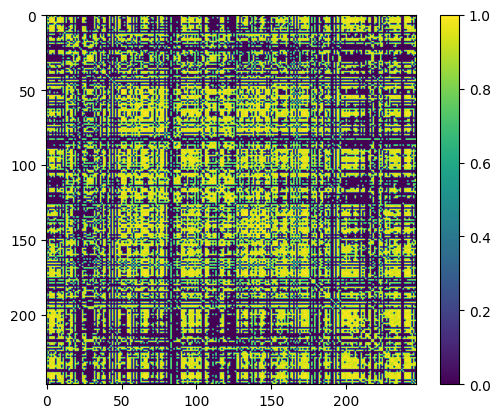

In [13]:
plt.imshow(sim_mask)
plt.colorbar()